# 08 · Linear algebra for robotics: SVD, least squares, manipulability

In [1]:
import mujoco, mujoco_menagerie as mm, numpy as np, matplotlib.pyplot as plt

def panda():
    model = mm.load("franka_emika_panda")
    data = mujoco.MjData(model)
    mujoco.mj_resetDataKeyframe(model, data, 0)
    mujoco.mj_forward(model, data)
    return model, data

def hand_jacobian(model, data, q=None):
    if q is not None:
        data.qpos[:7] = q
        mujoco.mj_forward(model, data)
    jacp, jacr = np.zeros((3, model.nv)), np.zeros((3, model.nv))
    mujoco.mj_jacBody(model, data, jacp, jacr, model.body("hand").id)
    return jacp[:, :7], jacr[:, :7]

def ellipse(A, n=200):
    th = np.linspace(0, 2 * np.pi, n)
    return A @ np.stack([np.cos(th), np.sin(th)])

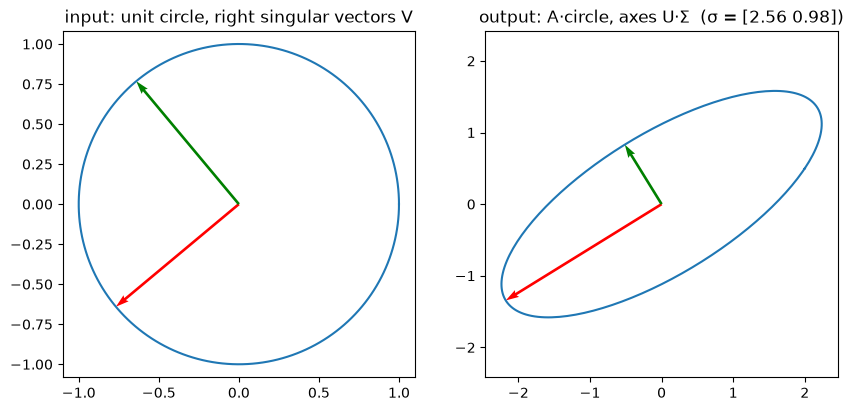

In [2]:
A = np.array([[2.0, 1.0], [0.5, 1.5]])
U, S, Vt = np.linalg.svd(A)
circle = ellipse(np.eye(2))
plt.figure(figsize=(10, 4.5))
plt.subplot(1, 2, 1); plt.plot(*circle); plt.quiver([0, 0], [0, 0], *Vt, angles="xy", scale_units="xy", scale=1, color=["r", "g"])
plt.axis("equal"); plt.title("input: unit circle, right singular vectors V")
plt.subplot(1, 2, 2); plt.plot(*(A @ circle)); plt.quiver([0, 0], [0, 0], *(U * S), angles="xy", scale_units="xy", scale=1, color=["r", "g"])
plt.axis("equal"); plt.title(f"output: A·circle, axes U·Σ  (σ = {S.round(2)})"); plt.show()

In [3]:
rng = np.random.default_rng(0)
true_offset, true_scale = np.array([0.012, -0.007, 0.004]), 1.02
measured = rng.uniform(-0.3, 0.3, (40, 3))
observed = true_scale * measured + true_offset + rng.normal(0, 0.002, (40, 3))
X = np.hstack([measured.reshape(-1, 1), np.kron(np.ones((40, 1)), np.eye(3))])
y = observed.reshape(-1)
sol, *_ = np.linalg.lstsq(X, y, rcond=None)
print("estimated scale ", sol[0].round(4), " true", true_scale)
print("estimated offset", sol[1:].round(4), " true", true_offset)
print("normal equations agree:", np.allclose(np.linalg.solve(X.T @ X, X.T @ y), sol))

estimated scale  1.0193  true 1.02
estimated offset [ 0.012  -0.0073  0.0038]  true [ 0.012 -0.007  0.004]
normal equations agree: True


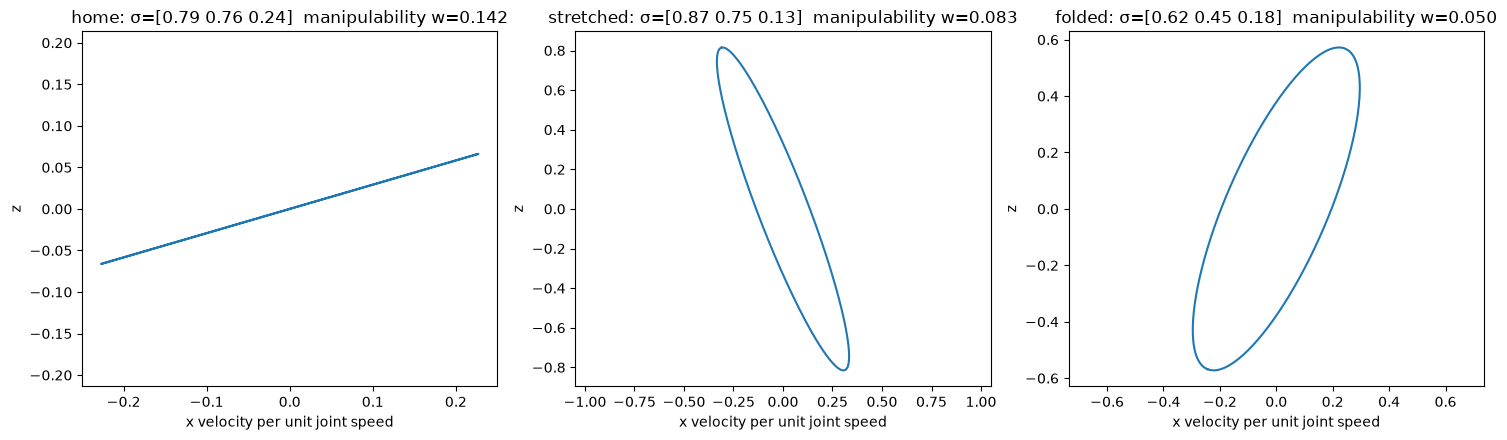

In [4]:
model, data = panda()
configs = {"home": data.qpos[:7].copy(),
           "stretched": np.array([0, 0.9, 0, -0.2, 0, 1.2, 0.785]),
           "folded": np.array([0, -0.6, 0, -2.9, 0, 2.5, 0.785])}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, q) in zip(axes, configs.items()):
    Jp, _ = hand_jacobian(model, data, q)
    U, S, _ = np.linalg.svd(Jp)
    w = np.sqrt(np.linalg.det(Jp @ Jp.T))
    E = U[[0, 2]][:, [0, 2]] @ np.diag(S[[0, 2]])
    ax.plot(*ellipse(E)); ax.axis("equal")
    ax.set_title(f"{name}: σ={S.round(2)}  manipulability w={w:.3f}")
    ax.set_xlabel("x velocity per unit joint speed"); ax.set_ylabel("z")
plt.tight_layout(); plt.show()

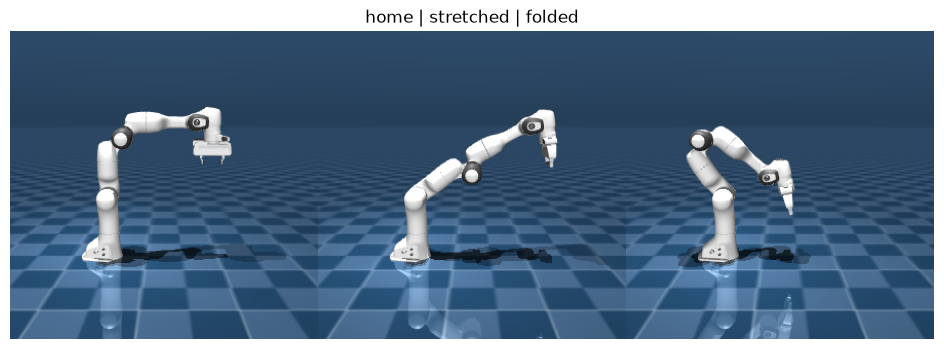

In [5]:
with mujoco.Renderer(model, 300, 300) as r:
    imgs = []
    for q in configs.values():
        data.qpos[:7] = q; mujoco.mj_forward(model, data)
        cam = mujoco.MjvCamera(); cam.lookat[:] = [0.3, 0, 0.4]; cam.distance, cam.azimuth, cam.elevation = 2.0, 90, -10
        r.update_scene(data, cam); imgs.append(r.render())
plt.figure(figsize=(12, 4)); plt.imshow(np.hstack(imgs)); plt.axis("off"); plt.title(" | ".join(configs)); plt.show()